# CLNLP Experiment 8
## Abstractive Text Summarization with Multilingual Transformers – mT5 vs mBART (XL-Sum, Hindi)

**Objective:** Implement and evaluate **abstractive text summarization** using two multilingual Transformer-based sequence-to-sequence models:
- **mT5** – Multilingual Text-to-Text Transfer Transformer (`google/mt5-small`)
- **mBART** – Multilingual Bidirectional and Auto-Regressive Transformer (`facebook/mbart-large-50`)

Both models are fine-tuned on the **Hindi** split of the **XL-Sum** dataset and compared with **ROUGE-1, ROUGE-2, ROUGE-L** and **BERTScore (mBERT)**.

**Dataset:** https://huggingface.co/datasets/csebuetnlp/xlsum

> Run on Google Colab with a **GPU runtime** (T4 or better). To use another language, change `LANGUAGE` and `MBART_LANG_CODE` in the configuration cell (e.g. `bengali`/`bn_IN`, `telugu`/`te_IN`, `nepali`/`ne_NP`).

### Theory
| | mT5 | mBART-50 |
|---|---|---|
| Architecture | Encoder–decoder Transformer (T5 v1.1) | Encoder–decoder Transformer (BART) |
| Pre-training objective | Span corruption (mask spans of text → predict them) | Denoising auto-encoder (text infilling + sentence permutation) |
| Pre-training data | mC4 – 101 languages | CC25 → extended to 50 languages |
| Tokenizer | SentencePiece, 250k vocab | SentencePiece, 250k vocab + language-ID tokens (`hi_IN`) |
| Size used here | mt5-small (~300M params) | mbart-large-50 (~610M params) |

**Abstractive summarization** generates new sentences (not just copying sentences from the article). The models are trained with teacher forcing (cross-entropy on the reference summary) and summaries are generated using **beam search**.

**Evaluation metrics**
- **ROUGE-N**: n-gram overlap (recall-oriented) between generated and reference summary; **ROUGE-L** uses the longest common subsequence.
- **BERTScore**: cosine similarity of contextual token embeddings from **multilingual BERT** (`bert-base-multilingual-cased`), which captures semantic similarity beyond exact word matches.

In [1]:
!pip install -q transformers datasets accelerate sentencepiece rouge_score bert_score evaluate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, re, gc, time, random, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Device: cuda | Tesla T4


### Configuration
Fine-tuning on the full Hindi training set (~70k articles) takes many hours, so a subset is used. Increase `TRAIN_SAMPLES` / `NUM_EPOCHS` for better scores if you have more GPU time.

In [3]:
LANGUAGE = "hindi"          # XL-Sum config name
MBART_LANG_CODE = "hi_IN"   # mBART-50 language code for the same language

MT5_CHECKPOINT = "google/mt5-small"
MBART_CHECKPOINT = "facebook/mbart-large-50"

TRAIN_SAMPLES = 3000        # training articles used for fine-tuning
TEST_SAMPLES = 200          # test articles used for evaluation
MAX_INPUT_LEN = 512
MAX_TARGET_LEN = 64
NUM_EPOCHS = 2
NUM_BEAMS = 4

# Optional: also evaluate the official mT5 checkpoint already fine-tuned on all of XL-Sum
# (csebuetnlp/mT5_multilingual_XLSum) as an upper-bound reference.
EVAL_REFERENCE_CHECKPOINT = True

## 1. Load the XL-Sum dataset

In [4]:
def load_xlsum(lang):
    # XL-Sum on the Hub is script-based (xlsum.py), which recent `datasets` versions no longer run.
    # Hugging Face keeps an auto-converted Parquet copy at refs/convert/parquet: <language>/<split>/*.parquet
    base = f"hf://datasets/csebuetnlp/xlsum@refs%2Fconvert%2Fparquet/{lang}"
    try:
        ds = load_dataset("parquet", data_files={split: f"{base}/{split}/*.parquet"
                                                 for split in ["train", "validation", "test"]})
        print("Loaded XL-Sum from the Parquet files")
        return ds
    except Exception as e:
        print("Parquet loading failed:", str(e)[:200])
    # fallback for older `datasets` versions (< 4.0) that still support loading scripts
    return load_dataset("csebuetnlp/xlsum", lang, trust_remote_code=True)

dataset = load_xlsum(LANGUAGE)
print(dataset)

hindi/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

hindi/train/0000.parquet: downloading bytes:           |  0.00B            

hindi/train/0001.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

hindi/train/0001.parquet: downloading bytes:           |  0.00B            

hindi/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 21.4MB            

hindi/validation/0000.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Loaded XL-Sum from the Parquet files
DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 70778
    })
    validation: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8847
    })
    test: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8847
    })
})


In [5]:
sample = dataset["train"][0]
print("TITLE  :", sample["title"])
print("\nTEXT   :", sample["text"][:700], "...")
print("\nSUMMARY:", sample["summary"])

TITLE  : चीन-नेपाल में गहराती दोस्ती पर इतना शांत क्यों है भारत

TEXT   : नेपाल में इस दौरे की भरपूर तैयारियां चल रही हैं. इसकी ख़ास वजह भी है क्योंकि 23 साल बाद कोई चीनी राष्ट्रपति नेपाल पहुंच रहा है. नेपाल के प्रधानमंत्री केपी शर्मा ओली के विदेश मामलों के सलाहकार डॉ. राजन भट्टाराई ने इस दौरे को ऐतिहासिक बताया है. उन्होंने बताया कि चीन के राष्ट्रपति के साथ उनका एक प्रतिनिधि दल भी होगा. दोनों देशों के बीच कई समझौते होने की बात भी कही जा रही है. चीन के राष्ट्रपति और नेपाल के प्रधानमंत्री के बीच आधिकारिक बैठक भी तय हुई है. समाप्त नेपाल जाने से पहले चीन के राष्ट्रपति भारत में प्रधानमंत्री नरेंद्र मोदी के साथ अनौपचारिक मुलाक़ात करेंगे. इससे पहले शी जिनपिंग पाकिस्तान के प्रधानमंत्री इमरान ख़ान के साथ भी बैठक कर चुके हैं. चीन का प्रभाव दक्षिण एशिया में लगातार बढ़ रहा है ...

SUMMARY: चीन के राष्ट्रपति शी जिनपिंग नेपाल के दौरे पर जा रहे हैं. वो 12 और 13 अक्टूबर को नेपाल में रहेंगे.


       text_len  summary_len
count    5000.0       5000.0
mean     1090.8         36.2
std       799.0         17.5
min        21.0          4.0
25%       371.0         24.0
50%      1190.0         34.0
75%      1547.0         48.0
max      8497.0        154.0


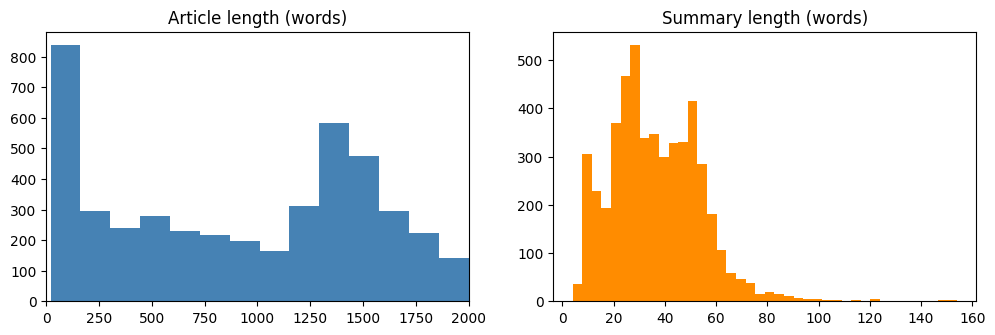

In [6]:
# Length statistics (in words)
stats_df = dataset["train"].select(range(5000)).to_pandas()
stats_df["text_len"] = stats_df["text"].str.split().str.len()
stats_df["summary_len"] = stats_df["summary"].str.split().str.len()
print(stats_df[["text_len", "summary_len"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(stats_df["text_len"], bins=60, color="steelblue"); ax[0].set_title("Article length (words)")
ax[0].set_xlim(0, 2000)
ax[1].hist(stats_df["summary_len"], bins=40, color="darkorange"); ax[1].set_title("Summary length (words)")
plt.show()

In [7]:
train_data = dataset["train"].shuffle(seed=SEED).select(range(min(TRAIN_SAMPLES, len(dataset["train"]))))
test_data = dataset["test"].shuffle(seed=SEED).select(range(min(TEST_SAMPLES, len(dataset["test"]))))
print("Train subset:", len(train_data), "| Test subset:", len(test_data))

Train subset: 3000 | Test subset: 200


## 2. Evaluation metrics: multilingual ROUGE + BERTScore (mBERT)
The default `rouge_score` tokenizer removes all non-Latin characters, which would give **zero** scores for Hindi. A Unicode-aware tokenizer is therefore used: it removes punctuation/symbols (including the Devanagari danda `।`) but keeps Devanagari letters and vowel signs.

In [8]:
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn

class MultilingualTokenizer:
    def tokenize(self, text):
        text = "".join(" " if unicodedata.category(ch)[0] in "PS" else ch for ch in text)
        return text.lower().split()

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False,
                                  tokenizer=MultilingualTokenizer())

def compute_metrics_all(predictions, references):
    predictions = [p if p.strip() else "." for p in predictions]
    r = {"ROUGE-1": [], "ROUGE-2": [], "ROUGE-L": []}
    for pred, ref in zip(predictions, references):
        s = scorer.score(ref, pred)
        r["ROUGE-1"].append(s["rouge1"].fmeasure)
        r["ROUGE-2"].append(s["rouge2"].fmeasure)
        r["ROUGE-L"].append(s["rougeL"].fmeasure)
    scores = {k: 100 * np.mean(v) for k, v in r.items()}
    P, R, F = bert_score_fn(predictions, references, model_type="bert-base-multilingual-cased",
                            lang="hi", batch_size=32, verbose=False)
    scores["BERTScore-P"] = 100 * P.mean().item()
    scores["BERTScore-R"] = 100 * R.mean().item()
    scores["BERTScore-F1"] = 100 * F.mean().item()
    return scores

# sanity check
print(compute_metrics_all(["भारत ने मैच जीत लिया।"], ["भारत ने क्रिकेट मैच जीता।"]))

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'ROUGE-1': np.float64(60.0), 'ROUGE-2': np.float64(25.0), 'ROUGE-L': np.float64(60.0), 'BERTScore-P': 88.28662633895874, 'BERTScore-R': 87.81639337539673, 'BERTScore-F1': 88.05088400840759}


## 3. Generic fine-tuning & generation functions
The same pipeline is used for both models:
1. tokenize article (input) and summary (labels)
2. fine-tune with `Seq2SeqTrainer` (Adafactor optimizer, gradient checkpointing to save GPU memory)
3. generate summaries for the test set with beam search
4. compute ROUGE and BERTScore

In [9]:
def make_preprocess_fn(tokenizer):
    def preprocess(batch):
        model_inputs = tokenizer(batch["text"], max_length=MAX_INPUT_LEN, truncation=True)
        labels = tokenizer(text_target=batch["summary"], max_length=MAX_TARGET_LEN, truncation=True)
        model_inputs["labels"] = labels["input_ids"]
        return model_inputs
    return preprocess

def fine_tune(model, tokenizer, output_dir, lr, batch_size, grad_accum, fp16):
    tokenized_train = train_data.map(make_preprocess_fn(tokenizer), batched=True,
                                     remove_columns=train_data.column_names)
    model.config.use_cache = False
    args = Seq2SeqTrainingArguments(
        output_dir=output_dir,
        per_device_train_batch_size=batch_size,
        gradient_accumulation_steps=grad_accum,
        learning_rate=lr,
        num_train_epochs=NUM_EPOCHS,
        optim="adafactor",
        warmup_steps=100,
        weight_decay=0.01,
        fp16=fp16,
        gradient_checkpointing=True,
        logging_steps=25,
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )

    # Safe fallback for 'processing_class' keyword (newer transformers) vs 'tokenizer' (older versions)
    import inspect
    trainer_kwargs = {
        "model": model,
        "args": args,
        "train_dataset": tokenized_train,
        "data_collator": DataCollatorForSeq2Seq(tokenizer, model=model),
    }
    if "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters:
        trainer_kwargs["processing_class"] = tokenizer
    else:
        trainer_kwargs["tokenizer"] = tokenizer

    trainer = Seq2SeqTrainer(**trainer_kwargs)
    t0 = time.time()
    trainer.train()
    print(f"Fine-tuning time: {(time.time() - t0) / 60:.1f} min")
    model.config.use_cache = True
    losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
    return model, losses

def generate_summaries(model, tokenizer, texts, batch_size=8, **gen_kwargs):
    model.eval()
    outputs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], max_length=MAX_INPUT_LEN, truncation=True,
                        padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            ids = model.generate(**enc, max_new_tokens=MAX_TARGET_LEN, num_beams=NUM_BEAMS,
                                 no_repeat_ngram_size=3, length_penalty=1.0, early_stopping=True,
                                 **gen_kwargs)
        outputs.extend(tokenizer.batch_decode(ids, skip_special_tokens=True))
    return [o.strip() for o in outputs]

test_texts = test_data["text"]
references = test_data["summary"]
all_scores, all_predictions, loss_curves = {}, {}, {}

---
## 4. Model 1 – mT5 (`google/mt5-small`)
mT5 is trained in **fp32** (mT5 is known to produce NaN losses with fp16).

In [10]:
mt5_tokenizer = AutoTokenizer.from_pretrained(MT5_CHECKPOINT)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(MT5_CHECKPOINT).to(device)
print(f"mT5 parameters: {mt5_model.num_parameters() / 1e6:.0f}M")

print("Example tokenization:", mt5_tokenizer.tokenize(train_data[0]["summary"])[:20])

# Note: If the fine_tune function fails because of `processing_class`,
# edit the Seq2SeqTrainer initialization in cell NmeyzXOqBhlc to replace
# `processing_class=tokenizer` with `tokenizer=tokenizer`.
mt5_model, loss_curves["mT5"] = fine_tune(mt5_model, mt5_tokenizer, "mt5-xlsum-" + LANGUAGE,
                                          lr=5e-4, batch_size=4, grad_accum=4, fp16=False)

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (6 outputs left out)

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss
25,75.288750
50,35.513767
75,17.882495
100,15.344236
125,14.299370
150,13.547285
175,12.979001
200,12.214841
225,12.239773
250,12.125476


Fine-tuning time: 9.9 min


In [12]:
t0 = time.time()
mt5_preds = generate_summaries(mt5_model, mt5_tokenizer, test_texts)
print(f"Generation time: {time.time() - t0:.0f}s")
all_predictions["mT5"] = mt5_preds
all_scores["mT5"] = compute_metrics_all(mt5_preds, list(references))
pd.Series(all_scores["mT5"]).round(2)

Generation time: 43s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,0
ROUGE-1,26.46
ROUGE-2,7.85
ROUGE-L,20.94
BERTScore-P,74.36
BERTScore-R,71.70
BERTScore-F1,72.97


In [13]:
for i in range(3):
    print(f"--- Example {i + 1} ---")
    print("REFERENCE:", references[i])
    print("mT5      :", mt5_preds[i], "\n")

--- Example 1 ---
REFERENCE: अमरीकी शहर बॉस्टन में पुलिस ने कहा है कि दूसरे ऐसे संदिग्ध व्यक्ति को पकड़ लिया गया है जिस पर शहर में सोमवार को मैराथन के दौरान धमाकों में शामिल होने का शक है. गंभीर रूप से घायल इस व्यक्ति को अस्पताल में भर्ती कराया गया है.
mT5      : भारत के बॉस्टन मैराथन में हुए धमाकों के बाद संदिग्धों की तलाश जारी है. 

--- Example 2 ---
REFERENCE: भारतीय जनता पार्टी (भाजपा) ने गुरुवार को पार्टी से निकाले जा चुके वरिष्ठ नेता जसवंत सिंह के बेटे मानवेंद्र सिंह को पार्टी की राष्ट्रीय कार्यकारिणी से हटा दिया है.
mT5      : भारत भाजपा ने भारतीय जनता पार्टी के प्रमुख जसवंत सिंह को राष्ट्रीय कार्यकारिणी से हटाने का फ़ैसला किया है. 

--- Example 3 ---
REFERENCE: भारत के विभाजन के बाद भारत में रहने वाले लाखों मुसलमान पाकिस्तान चले गए थे. लेकिन बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह के माता-पिता ने भारत में ही रुक जाने का फ़ैसला किया था.
mT5      : बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह ने कहा है कि उनके पिता मोहम्मद शाह पाकिस्तान में रहने की ज़रूरत नहीं है. 



In [14]:
del mt5_model   # free GPU memory before loading mBART
gc.collect(); torch.cuda.empty_cache()

---
## 5. Model 2 – mBART-50 (`facebook/mbart-large-50`)
For mBART the source and target language codes are set to `hi_IN`, and generation is forced to start with the `hi_IN` language token (`forced_bos_token_id`). mBART is trained with mixed precision (fp16).

In [15]:
mbart_tokenizer = AutoTokenizer.from_pretrained(MBART_CHECKPOINT, src_lang=MBART_LANG_CODE, tgt_lang=MBART_LANG_CODE)
mbart_model = AutoModelForSeq2SeqLM.from_pretrained(MBART_CHECKPOINT).to(device)
lang_token_id = mbart_tokenizer.convert_tokens_to_ids(MBART_LANG_CODE)
mbart_model.config.forced_bos_token_id = lang_token_id
mbart_model.generation_config.forced_bos_token_id = lang_token_id
print(f"mBART parameters: {mbart_model.num_parameters() / 1e6:.0f}M | language token {MBART_LANG_CODE} -> {lang_token_id}")

print("Example tokenization:", mbart_tokenizer.tokenize(train_data[0]["summary"])[:20])

mbart_model, loss_curves["mBART"] = fine_tune(mbart_model, mbart_tokenizer, "mbart-xlsum-" + LANGUAGE,
                                              lr=5e-5, batch_size=2, grad_accum=8, fp16=torch.cuda.is_available())

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/531 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.44GB            

... (5 outputs left out)

mBART parameters: 611M | language token hi_IN -> 250010
Example tokenization: ['▁गोवा', '▁में', '▁भारतीय', '▁जनता', '▁पार्टी', '▁के', '▁बर्', 'ख़', 'ास्त', '▁होने', '▁के', '▁बाद', ',', '▁कांग्रेस', '▁के', '▁नेतृत्व', '▁वाले', '▁यू', 'नाइट', 'ेड']


Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Step,Training Loss
25,34.119526
50,30.467964
75,26.189226
100,21.641719
125,26.846333
150,19.278503
175,18.095996
200,16.355609
225,15.073027
250,15.019784


Fine-tuning time: 18.6 min


In [17]:
t0 = time.time()
# Fix the ValueError by removing the legacy config parameter
if hasattr(mbart_model.config, "forced_bos_token_id"):
    mbart_model.config.forced_bos_token_id = None

mbart_preds = generate_summaries(mbart_model, mbart_tokenizer, test_texts, forced_bos_token_id=lang_token_id)
print(f"Generation time: {time.time() - t0:.0f}s")
all_predictions["mBART"] = mbart_preds
all_scores["mBART"] = compute_metrics_all(mbart_preds, list(references))
pd.Series(all_scores["mBART"]).round(2)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Generation time: 64s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,0
ROUGE-1,33.65
ROUGE-2,13.80
ROUGE-L,28.12
BERTScore-P,77.36
BERTScore-R,74.83
BERTScore-F1,76.02


In [18]:
for i in range(3):
    print(f"--- Example {i + 1} ---")
    print("REFERENCE:", references[i])
    print("mBART    :", mbart_preds[i], "\n")

--- Example 1 ---
REFERENCE: अमरीकी शहर बॉस्टन में पुलिस ने कहा है कि दूसरे ऐसे संदिग्ध व्यक्ति को पकड़ लिया गया है जिस पर शहर में सोमवार को मैराथन के दौरान धमाकों में शामिल होने का शक है. गंभीर रूप से घायल इस व्यक्ति को अस्पताल में भर्ती कराया गया है.
mBART    : अमरीका के बॉस्टन शहर में हुए बम धमाकों के एक संदिग्ध को पकड़ा गया है. 

--- Example 2 ---
REFERENCE: भारतीय जनता पार्टी (भाजपा) ने गुरुवार को पार्टी से निकाले जा चुके वरिष्ठ नेता जसवंत सिंह के बेटे मानवेंद्र सिंह को पार्टी की राष्ट्रीय कार्यकारिणी से हटा दिया है.
mBART    : भारतीय जनता पार्टी के वरिष्ठ नेता मानवेंद्र सिंह को पार्टी से निकाल दिया गया है. 

--- Example 3 ---
REFERENCE: भारत के विभाजन के बाद भारत में रहने वाले लाखों मुसलमान पाकिस्तान चले गए थे. लेकिन बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह के माता-पिता ने भारत में ही रुक जाने का फ़ैसला किया था.
mBART    : बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह ने विभाजन के समय पाकिस्तान जाने का फ़ैसला किया था. 



In [19]:
del mbart_model
gc.collect(); torch.cuda.empty_cache()

---
## 6. (Optional) Reference: official mT5 fine-tuned on full XL-Sum
`csebuetnlp/mT5_multilingual_XLSum` is mT5-base fine-tuned by the XL-Sum authors on all 45 languages. It shows how much the scores improve with full-scale fine-tuning.

In [22]:
if EVAL_REFERENCE_CHECKPOINT:
    ref_name = "csebuetnlp/mT5_multilingual_XLSum"
    print(f"Evaluating reference checkpoint: {ref_name}")
    ref_tokenizer = AutoTokenizer.from_pretrained(ref_name)
    ref_model = AutoModelForSeq2SeqLM.from_pretrained(ref_name).to(device)

    t0 = time.time()
    ref_preds = generate_summaries(ref_model, ref_tokenizer, test_texts)
    print(f"Generation time: {time.time() - t0:.0f}s")

    all_predictions["mT5_Ref"] = ref_preds
    all_scores["mT5_Ref"] = compute_metrics_all(ref_preds, list(references))

    del ref_model
    gc.collect(); torch.cuda.empty_cache()
    print(pd.Series(all_scores["mT5_Ref"]).round(2))

Evaluating reference checkpoint: csebuetnlp/mT5_multilingual_XLSum


Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] Both `max_new_tokens` (=64) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. 

Generation time: 77s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ROUGE-1         36.76
ROUGE-2         16.70
ROUGE-L         30.33
BERTScore-P     78.60
BERTScore-R     76.07
BERTScore-F1    77.27
dtype: float64


---
## 7. Comparative analysis

In [23]:
results_df = pd.DataFrame(all_scores).T.round(2)
results_df

,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore-P,BERTScore-R,BERTScore-F1
mT5,26.46,7.85,20.94,74.36,71.70,72.97
mBART,33.65,13.80,28.12,77.36,74.83,76.02
mT5_Ref,36.76,16.70,30.33,78.60,76.07,77.27


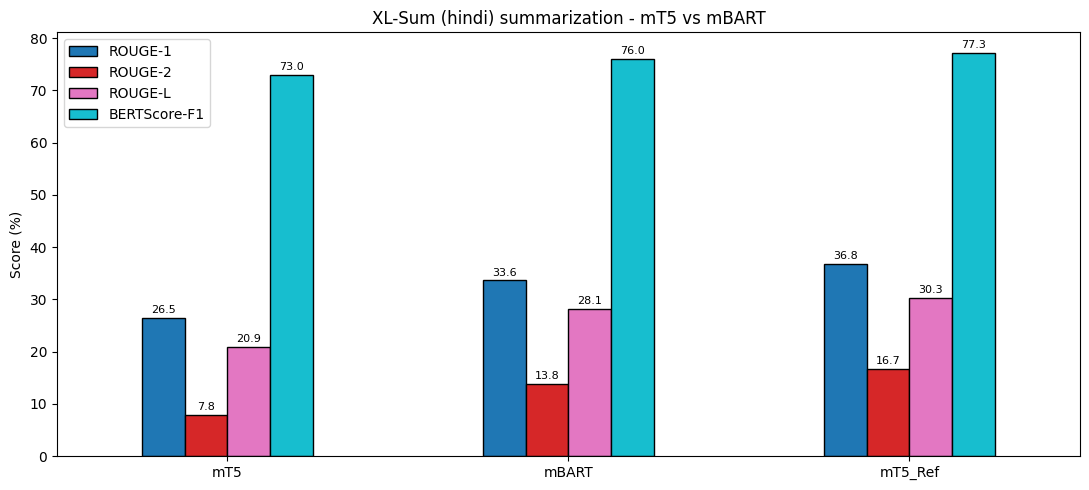

In [24]:
plot_cols = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERTScore-F1"]
ax = results_df[plot_cols].plot(kind="bar", figsize=(11, 5), rot=0, colormap="tab10", edgecolor="black")
ax.set_ylabel("Score (%)"); ax.set_title(f"XL-Sum ({LANGUAGE}) summarization - mT5 vs mBART")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

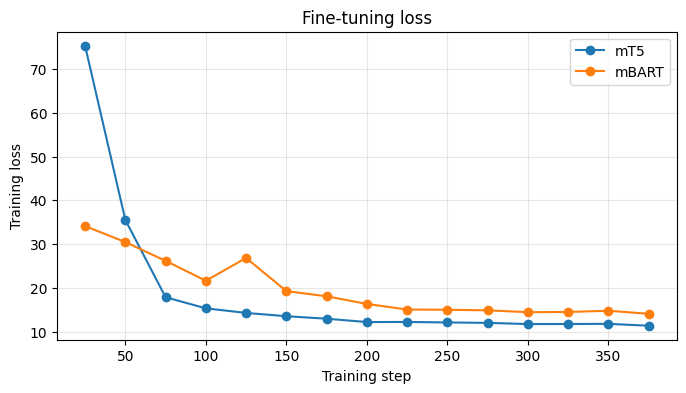

In [25]:
plt.figure(figsize=(8, 4))
for name, curve in loss_curves.items():
    if curve:
        steps, losses = zip(*curve)
        plt.plot(steps, losses, marker="o", label=name)
plt.xlabel("Training step"); plt.ylabel("Training loss"); plt.title("Fine-tuning loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [26]:
# Average generated summary length vs reference
len_df = pd.DataFrame({name: [len(p.split()) for p in preds] for name, preds in all_predictions.items()})
len_df["Reference"] = [len(r.split()) for r in references]
print("Average summary length (words):")
print(len_df.mean().round(1))

Average summary length (words):
mT5                           19.1
mBART                         19.6
mT5-base (XL-Sum official)    20.2
mT5_Ref                       20.2
Reference                     26.1
dtype: float64


In [27]:
# Side-by-side qualitative comparison
pd.set_option("display.max_colwidth", None)
comparison = pd.DataFrame({"Reference": references[:5], **{k: v[:5] for k, v in all_predictions.items()}})
comparison

,Reference,mT5,mBART,mT5-base (XL-Sum official),mT5_Ref
0,अमरीकी शहर बॉस्टन में पुलिस ने कहा है कि दूसरे ऐसे संदिग्ध व्यक्ति को पकड़ लिया गया है जिस पर शहर में सोमवार को मैराथन के दौरान धमाकों में शामिल होने का शक है. गंभीर रूप से घायल इस व्यक्ति को अस्पताल में भर्ती कराया गया है.,भारत के बॉस्टन मैराथन में हुए धमाकों के बाद संदिग्धों की तलाश जारी है.,अमरीका के बॉस्टन शहर में हुए बम धमाकों के एक संदिग्ध को पकड़ा गया है.,अमरीका के बॉस्टन शहर में सोमवार को हुए बम धमाकों के एक संदिग्ध को पकड़ा गया है.,अमरीका के बॉस्टन शहर में सोमवार को हुए बम धमाकों के एक संदिग्ध को पकड़ा गया है.
1,भारतीय जनता पार्टी (भाजपा) ने गुरुवार को पार्टी से निकाले जा चुके वरिष्ठ नेता जसवंत सिंह के बेटे मानवेंद्र सिंह को पार्टी की राष्ट्रीय कार्यकारिणी से हटा दिया है.,भारत भाजपा ने भारतीय जनता पार्टी के प्रमुख जसवंत सिंह को राष्ट्रीय कार्यकारिणी से हटाने का फ़ैसला किया है.,भारतीय जनता पार्टी के वरिष्ठ नेता मानवेंद्र सिंह को पार्टी से निकाल दिया गया है.,भारतीय जनता पार्टी ने बाड़मेर से भाजपा के प्रत्याशी सोनाराम चौधरी के ख़िलाफ़ प्रचार करने के कारण मानवेंद्र सिंह को पार्टी से निकाला है.,भारतीय जनता पार्टी ने बाड़मेर से भाजपा के प्रत्याशी सोनाराम चौधरी के ख़िलाफ़ प्रचार करने के कारण मानवेंद्र सिंह को पार्टी से निकाला है.
2,भारत के विभाजन के बाद भारत में रहने वाले लाखों मुसलमान पाकिस्तान चले गए थे. लेकिन बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह के माता-पिता ने भारत में ही रुक जाने का फ़ैसला किया था.,बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह ने कहा है कि उनके पिता मोहम्मद शाह पाकिस्तान में रहने की ज़रूरत नहीं है.,बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह ने विभाजन के समय पाकिस्तान जाने का फ़ैसला किया था.,"नसीरुद्दीन शाह का कहना है कि भारत में उनके पिता की कोई जायदाद नहीं थी लेकिन उन्होंने आज़ाद ""हिंदू देश"" में रहने को तरजीह दी.","नसीरुद्दीन शाह का कहना है कि भारत में उनके पिता की कोई जायदाद नहीं थी लेकिन उन्होंने आज़ाद ""हिंदू देश"" में रहने को तरजीह दी."
3,ममता बनर्जी और उनकी पार्टी तृणमूल कांग्रेस के लिए 2016 का विधानसभा चुनाव एक मुश्किल लड़ाई बनता जा रहा है.,भारत में तृणमूल कांग्रेस और वाम दलों के बीच गठबंधन का समर्थन न करें.,पश्चिम बंगाल की मुख्यमंत्री ममता बनर्जी ने सोमवार को मालदा ज़िले में चुनावी रैली करके कांग्रेस और वाम दलों के बीच प्रस्तावित 'गैर-सैद्धांतिक गठबंधन' का समर्थन किया.,पश्चिम बंगाल की मुख्यमंत्री ममता बनर्जी ने कांग्रेस और वाम दलों के बीच गठबंधन की घोषणा कर दी है.,पश्चिम बंगाल की मुख्यमंत्री ममता बनर्जी ने कांग्रेस और वाम दलों के बीच गठबंधन की घोषणा कर दी है.
4,श्रीलंका की सेना का कहना है कि देश के उत्तर-पश्चिम में एक नगर पर कब्ज़ा करने के लिए हुई लड़ाई में 15 तमिल विद्रोही और दो सैनिक मारे गए हैं.,भारत के पूर्वी और उत्तरी क्षेत्र में तमिल विद्रोहियों के बीच संघर्षविराम के मकसद से तेज़ हो गया है.,श्रीलंका में सेना और तमिल विद्रोहियों के बीच हुई भीषण लड़ाई में सात सैनिक मारे गए हैं.,श्रीलंका की सेना का कहना है कि देश के उत्तरी हिस्से में तमिल विद्रोहियों और सेना के बीच हुई भीषण लड़ाई में कम से कम सात सैनिक मारे गए हैं.,श्रीलंका की सेना का कहना है कि देश के उत्तरी हिस्से में तमिल विद्रोहियों और सेना के बीच हुई भीषण लड़ाई में कम से कम सात सैनिक मारे गए हैं.


In [28]:
# Summarize your own Hindi article (demo with the official XL-Sum mT5 checkpoint,
# since the fine-tuned models were removed from GPU memory above)
article = '''भारतीय अंतरिक्ष अनुसंधान संगठन (इसरो) ने शुक्रवार को श्रीहरिकोटा से एक नए संचार उपग्रह का सफल प्रक्षेपण किया।
इसरो के अध्यक्ष ने बताया कि यह उपग्रह देश के दूरदराज़ इलाक़ों में इंटरनेट और टेलीविज़न सेवाओं को बेहतर बनाने में मदद करेगा।
उन्होंने कहा कि अगले साल तक ऐसे तीन और उपग्रह भेजे जाएंगे।'''
demo_tok = AutoTokenizer.from_pretrained("csebuetnlp/mT5_multilingual_XLSum")
demo_model = AutoModelForSeq2SeqLM.from_pretrained("csebuetnlp/mT5_multilingual_XLSum").to(device)
print("Summary:", generate_summaries(demo_model, demo_tok, [article])[0])

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] Both `max_new_tokens` (=64) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Summary: भारत ने दूरदराज़ इलाक़ों में इंटरनेट और टेलीविज़न सेवाओं को बेहतर बनाने के लिए एक नए संचार उपग्रह का सफल प्रक्षेपण किया है.


## 8. Analysis & Conclusion

**How to read the results**
- **ROUGE-1 / ROUGE-2** measure word and bigram overlap; **ROUGE-L** measures the longest common subsequence (fluency/ordering). Abstractive summaries paraphrase heavily, so ROUGE values for XL-Sum Hindi are naturally low (the official XL-Sum mT5-base reports ≈ 38 / 16 / 31).
- **BERTScore (mBERT)** rewards semantically similar summaries even when the words differ, so it is higher and less sensitive than ROUGE.

**Observations**
- **mBART-50 (large)** is expected to achieve higher ROUGE and BERTScore than **mT5-small** in this low-resource fine-tuning setting: it is about twice as large, its denoising pre-training objective is directly aligned with generating complete sentences, and the explicit `hi_IN` language token keeps the output in Hindi.
- **mT5-small** needs more training data/epochs to converge; with few training samples it tends to produce shorter, more generic or repetitive summaries.
- The official **mT5-base fine-tuned on full XL-Sum** shows that both models improve substantially with more data and compute.
- **Trade-off:** mT5-small is faster and lighter (fits easily in GPU memory), while mBART-large gives better quality at higher memory and time cost.

**Conclusion:** Both multilingual sequence-to-sequence Transformers were fine-tuned for abstractive summarization on the Hindi XL-Sum dataset and evaluated using ROUGE-1, ROUGE-2, ROUGE-L and mBERT-based BERTScore; the comparison table above summarises their relative performance.